In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping

I0000 00:00:1793714200.698271    8361 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793714200.698931    8361 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793714200.755079    8361 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793714202.311421    8361 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
folder = "Celebrity Faces Dataset"
classes = sorted(os.listdir(folder)); X, y = [], []
for idx,c in enumerate(classes):
    for f in os.listdir(os.path.join(folder,c)):
        if f.lower().endswith(("jpg","jpeg","png")):
            X.append(img_to_array(load_img(os.path.join(folder,c,f),target_size=(64,64)))); y.append(idx)
X, y = np.array(X), np.array(y)
print("Images:",X.shape,"Labels:",y.shape,"Classes:",len(classes))

Images: (1800, 64, 64, 3) Labels: (1800,) Classes: 17


In [4]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
X_train, X_test = X_train/255.0, X_test/255.0

In [5]:
base = tf.keras.Sequential([tf.keras.Input(shape=(64,64,3)),
        layers.Conv2D(16,3,activation="relu"), layers.MaxPooling2D(), layers.Flatten(),
        layers.Dense(32,activation="relu"), layers.Dense(len(classes),activation="softmax")])
base.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
base.fit(X_train,y_train,epochs=10,validation_split=0.1,verbose=0)
print("Baseline accuracy:",base.evaluate(X_test,y_test,verbose=0)[1])

E0000 00:00:1793718108.352964    8361 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Baseline accuracy: 0.13333334028720856


In [6]:
model = tf.keras.Sequential([tf.keras.Input(shape=(64,64,3)),
        layers.Conv2D(32,3,activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(64,3,activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Flatten(), layers.Dense(64,activation="relu"), layers.Dropout(0.3),
        layers.Dense(len(classes),activation="softmax")])
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
model.fit(X_train,y_train,epochs=40,validation_split=0.1,verbose=0,
          callbacks=[EarlyStopping(monitor="val_accuracy",patience=5,restore_best_weights=True)])

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Improved accuracy: 0.058333333333333334
                    precision    recall  f1-score   support

    Angelina Jolie       0.00      0.00      0.00        20
         Brad Pitt       0.00      0.00      0.00        20
 Denzel Washington       0.00      0.00      0.00        20
      Hugh Jackman       0.00      0.00      0.00        20
 Jennifer Lawrence       0.00      0.00      0.00        20
       Johnny Depp       0.00      0.00      0.00        20
      Kate Winslet       0.00      0.00      0.00        20
 Leonardo DiCaprio       0.00      0.00      0.00        20
         Megan Fox       0.00      0.00      0.00        20
   Natalie Portman       0.10      0.05      0.07        20
     Nicole Kidman       0.00      0.00      0.00        20
  Robert Downey Jr       0.00      0.00      0.00        20
    Sandra Bullock       0.00      0.00      0.00        20
Scarlett Johansson       0.00      0.00      0.00        40
        Tom Cruise 

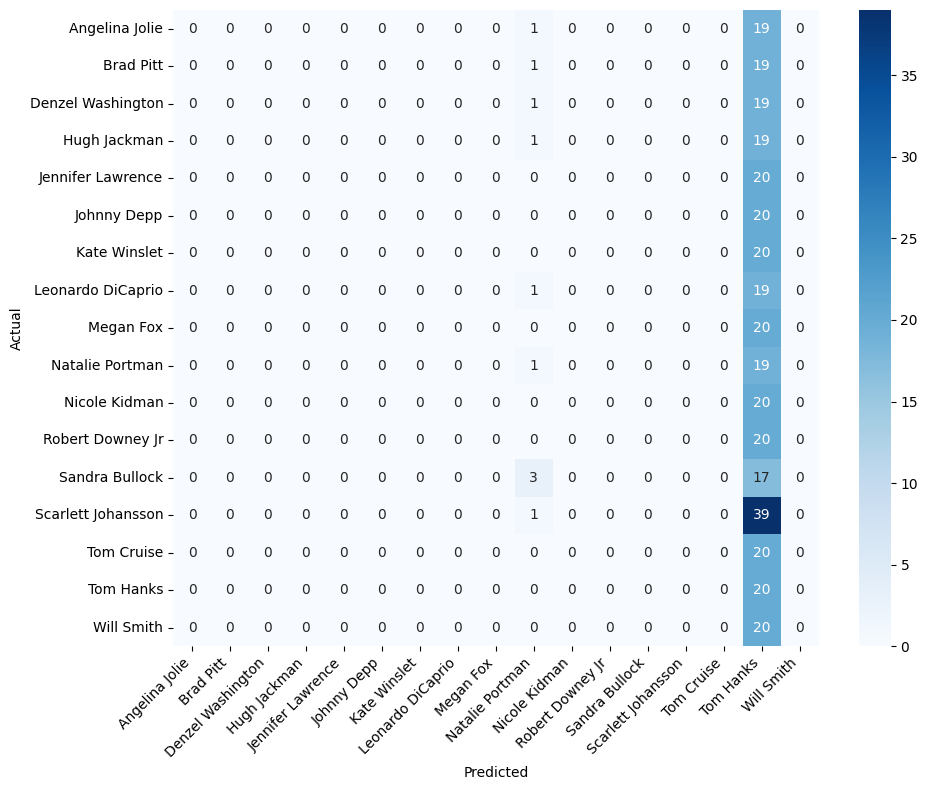

In [7]:
pred = np.argmax(model.predict(X_test),axis=1)
print("Improved accuracy:",accuracy_score(y_test,pred))
print(classification_report(y_test,pred,target_names=classes,zero_division=0))
plt.figure(figsize=(10,8))
sns.heatmap(confusion_matrix(y_test,pred),annot=True,fmt="d",cmap="Blues",xticklabels=classes,yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=45,ha="right"); plt.tight_layout(); plt.show()